# Comparing Classifiers to Predict Bank Term-Deposit Subscriptions

**Models compared:** K-Nearest Neighbors · Logistic Regression · Decision Tree · Support Vector Machine
**Data:** Portuguese bank telemarketing campaigns, May 2008 – Nov 2010 (UCI Bank Marketing, *bank-additional-full*; Moro, Cortez & Rita, 2014)
**Method:** CRISP-DM (Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment recommendations)

**Notebook map**
1. Business Understanding
2. Data Understanding (descriptive & inferential statistics)
3. Data Preparation
4. Modeling (baseline → default models → cross-validated grid search)
5. Evaluation & Model Interpretation
6. Robustness Checks
7. **Findings** (plain-language summary and actionable items)
8. Next Steps & Recommendations

## 1. Business Understanding

**Situation.** A Portuguese bank sells a long-term *term deposit* through outbound phone campaigns. Every call costs agent time, and mass calling is inefficient: only about 1 in 9 calls in this data ends in a subscription. Moro et al. (2014) note that banks are under pressure to *"make fewer contacts but keep roughly the same number of successes."*

**Business problem.** Which clients should the call center phone first, so that the bank wins the most subscriptions per call made?

**Data-science translation.** Binary classification: predict `y` (client subscribes: yes/no) from information the bank has **before dialing**. The model's real job is to *rank* clients by likelihood of subscribing, so campaign managers can call the top of the list and skip the bottom.

**Success criteria.**
- A model that ranks prospects clearly better than random calling (measured with ROC-AUC and cumulative gains/lift).
- A model whose drivers are understandable enough to turn into campaign decisions (who to call, when, how).
- A clear recommendation on which of the four classifiers to use and why.

**Important design decision – no call duration.** The dataset documentation warns that `duration` (call length in seconds) is only known *after* the call, at which point the outcome is essentially known. Including it would produce a flattering but unusable model. **`duration` is excluded** from all models. Section 6 quantifies how much it would inflate performance.

## 2. Data Understanding

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve, precision_recall_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

In [2]:
# The file is semicolon-separated
df_raw = pd.read_csv("data/bank-additional-full.csv", sep=";")
print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
df_raw.head()

Rows: 41,188   Columns: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# Data types, and a check for true nulls
summary = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "n_unique": df_raw.nunique(), "nulls": df_raw.isna().sum()})
summary

,dtype,n_unique,nulls
age,int64,78,0
job,str,12,0
marital,str,4,0
education,str,8,0
default,str,3,0
housing,str,3,0
loan,str,3,0
contact,str,2,0
month,str,10,0
day_of_week,str,5,0


There are no formal nulls, but the data dictionary says missing values in categorical columns are coded as the string `"unknown"`. Let's measure them, plus duplicates and the target balance.

In [4]:
cat_cols_raw = df_raw.select_dtypes(include=["object", "string"]).columns.drop("y")
unknown_counts = (df_raw[cat_cols_raw] == "unknown").sum()
unknown_pct = (unknown_counts / len(df_raw) * 100).round(1)
print("Rows coded 'unknown' per column:")
print(pd.DataFrame({"count": unknown_counts, "pct": unknown_pct}).query("count > 0").sort_values("count", ascending=False))
print(f"\nExact duplicate rows: {df_raw.duplicated().sum()}")
print(f"Clients never contacted before (pdays == 999): {(df_raw['pdays'] == 999).mean():.1%}")

Rows coded 'unknown' per column:
           count   pct
default     8597  20.9
education   1731   4.2
housing      990   2.4
loan         990   2.4
job          330   0.8
marital       80   0.2

Exact duplicate rows: 12
Clients never contacted before (pdays == 999): 96.3%


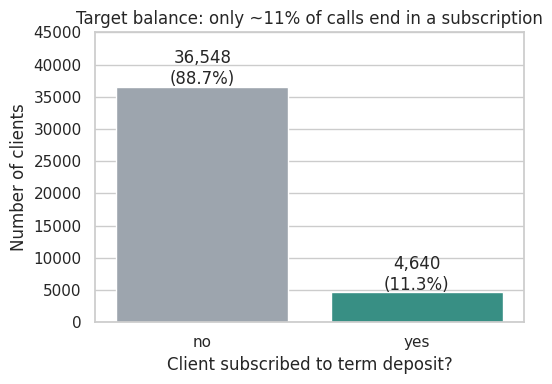

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 4))
order = ["no", "yes"]
sns.countplot(data=df_raw, x="y", order=order, palette=["#9aa5b1", "#2a9d8f"], ax=ax)
for i, lab in enumerate(order):
    n = (df_raw["y"] == lab).sum()
    ax.text(i, n + 400, f"{n:,}\n({n / len(df_raw):.1%})", ha="center")
ax.set_title("Target balance: only ~11% of calls end in a subscription")
ax.set_xlabel("Client subscribed to term deposit?")
ax.set_ylabel("Number of clients")
ax.set_ylim(0, 45000)
plt.tight_layout()
plt.show()

**Observations**
- The target is **imbalanced (~89% "no" / 11% "yes")**. A model that always says "no" would be 88.7% *accurate* while finding zero customers, so accuracy is a poor yardstick here (see Section 4.1).
- `default` has the most `unknown` values (~21%). An unknown credit-default status turns out to be informative (those clients subscribe at only ~5% vs ~13% for "no"), and the data dictionary suggests treating it as a class label, so `unknown` is kept as its own category rather than deleted or imputed.
- 12 exact duplicate rows exist; they will be removed.
- 96% of clients were never contacted in a previous campaign (`pdays == 999`, a sentinel value, not a real number of days).

### 2.1 Descriptive statistics

In [6]:
df_raw.drop(columns="y").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


Notes: `age` runs 17–98 (median 38). `campaign` (contacts during this campaign) has a long right tail up to 56 calls to a single client. `pdays` and `previous` are dominated by the "never contacted" case. The five economic indicators (`emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`) are national figures that change only quarterly/monthly, so they mostly describe *when* a call happened.

### 2.2 Subscription rate by client and campaign characteristics

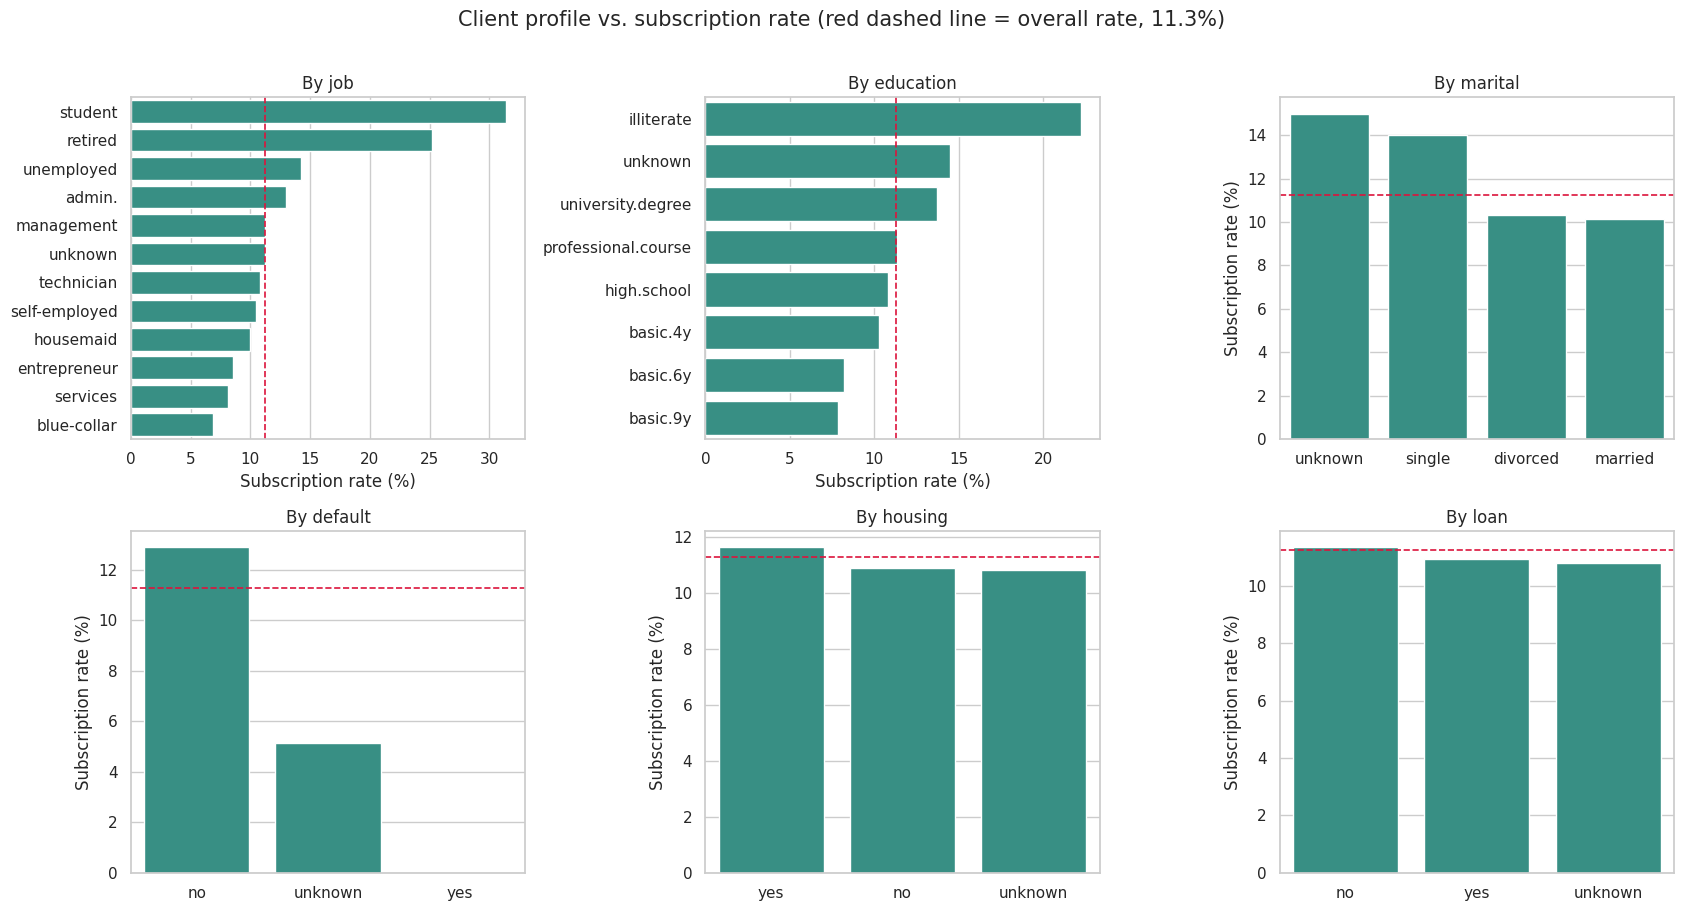

In [7]:
df_eda = df_raw.copy()
df_eda["subscribed"] = (df_eda["y"] == "yes").astype(int)
base_rate = df_eda["subscribed"].mean()

def rate_plot(ax, col, order=None, horizontal=False):
    """Bar plot of subscription rate per category, with the overall rate as a reference line."""
    rates = df_eda.groupby(col)["subscribed"].mean() * 100
    order = order if order is not None else rates.sort_values(ascending=False).index
    if horizontal:
        sns.barplot(x=rates.loc[order].values, y=list(order), color="#2a9d8f", ax=ax)
        ax.axvline(base_rate * 100, color="crimson", ls="--", lw=1.2)
        ax.set_xlabel("Subscription rate (%)"); ax.set_ylabel("")
    else:
        sns.barplot(x=list(order), y=rates.loc[order].values, color="#2a9d8f", ax=ax)
        ax.axhline(base_rate * 100, color="crimson", ls="--", lw=1.2)
        ax.set_ylabel("Subscription rate (%)"); ax.set_xlabel("")
    ax.set_title(f"By {col}")

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
rate_plot(axes[0, 0], "job", horizontal=True)
rate_plot(axes[0, 1], "education", horizontal=True)
rate_plot(axes[0, 2], "marital")
rate_plot(axes[1, 0], "default")
rate_plot(axes[1, 1], "housing")
rate_plot(axes[1, 2], "loan")
fig.suptitle("Client profile vs. subscription rate (red dashed line = overall rate, 11.3%)", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

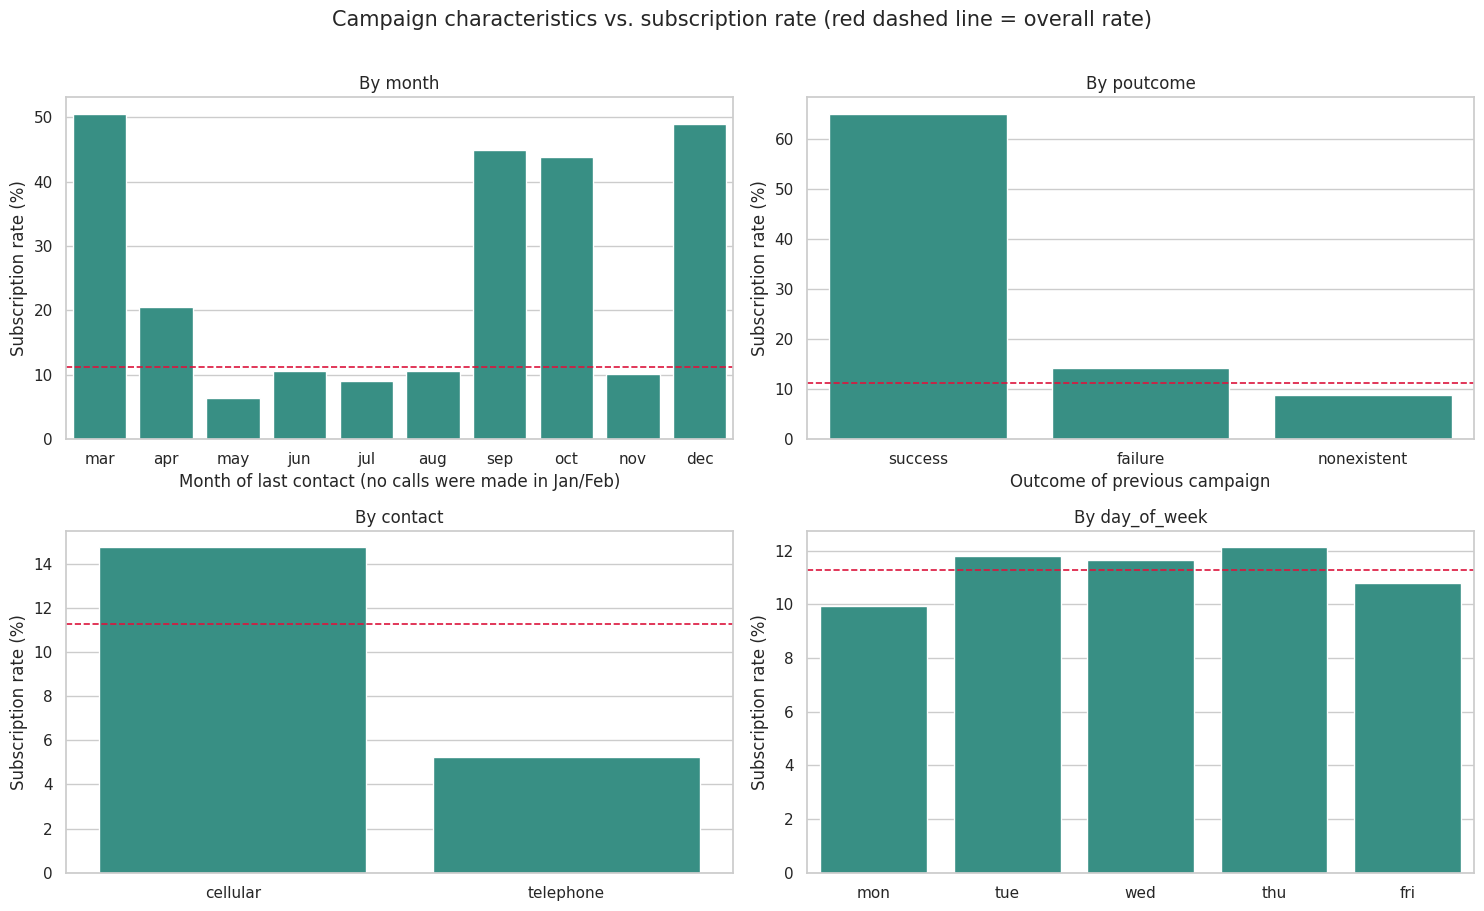

Number of calls per month (note how rare the highest-converting months are):
month  mar   apr    may   jun   jul   aug  sep  oct   nov  dec
calls  546  2632  13769  5318  7174  6178  570  718  4101  182


In [8]:
months = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
rate_plot(axes[0, 0], "month", order=months)
rate_plot(axes[0, 1], "poutcome")
rate_plot(axes[1, 0], "contact")
rate_plot(axes[1, 1], "day_of_week", order=["mon", "tue", "wed", "thu", "fri"])
axes[0, 0].set_xlabel("Month of last contact (no calls were made in Jan/Feb)")
axes[0, 1].set_xlabel("Outcome of previous campaign")
fig.suptitle("Campaign characteristics vs. subscription rate (red dashed line = overall rate)", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

print("Number of calls per month (note how rare the highest-converting months are):")
print(df_eda["month"].value_counts().reindex(months).to_frame("calls").T.to_string())

**What the charts show**
- **Previous success is the strongest signal:** clients who subscribed in an earlier campaign (`poutcome = success`) convert at roughly 65%, versus ~9% for first-timers.
- **Seasonality:** March, September, October and December have conversion rates of 40–50%, but they account for only a few hundred calls each; May has by far the most calls and one of the lowest rates.
- **Profile:** students (31%) and retirees (25%) subscribe far more than average; blue-collar workers (7%), services (8%) and entrepreneurs (9%) less. Clients reached on **cellular** phones convert about 2.8× more often (14.7% vs 5.2%) than those on landline telephone.
- Day of week, marital status, and housing/personal-loan status show only small differences.
- **Caveat on small groups:** `default = yes` has only 3 clients and `education = illiterate` only 18, so their extreme rates are unreliable. The high-converting months (Mar, Sep, Oct, Dec) have only 182–718 calls each and coincide with low-interest-rate periods, so *month* partly stands in for the economic cycle and campaign design rather than being a pure "best time to call" effect.

### 2.3 Numeric features vs. subscription

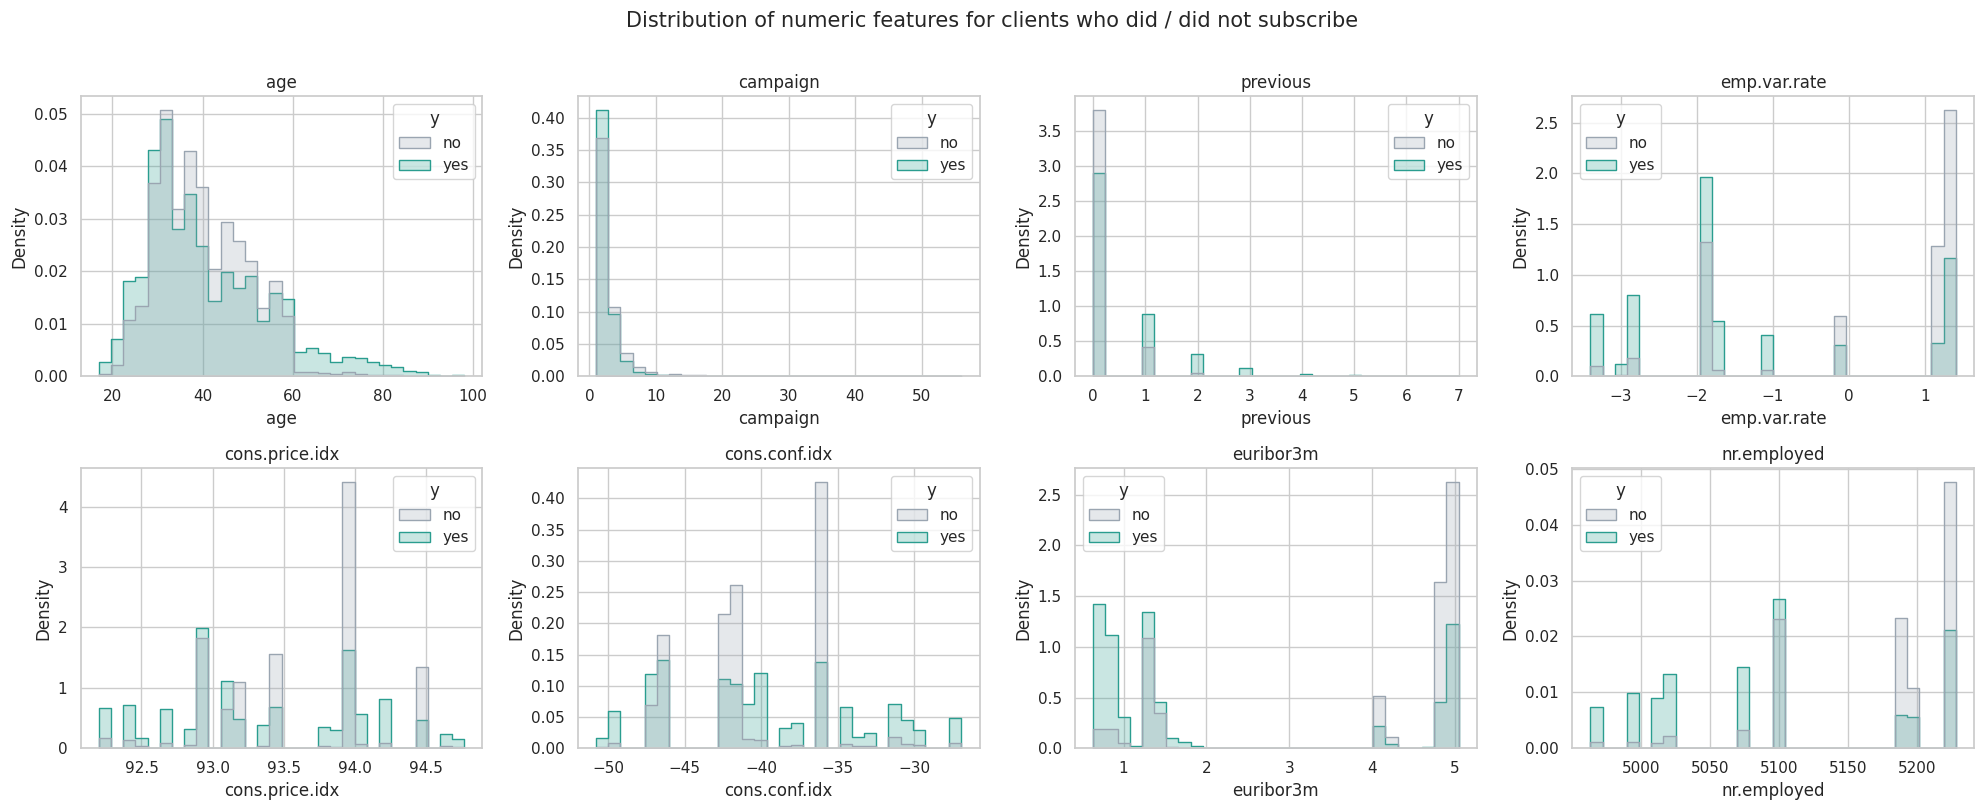

In [9]:
num_cols_eda = ["age", "campaign", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), num_cols_eda):
    sns.histplot(data=df_eda, x=col, hue="y", stat="density", common_norm=False, element="step",
                 bins=30, palette={"no": "#9aa5b1", "yes": "#2a9d8f"}, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
fig.suptitle("Distribution of numeric features for clients who did / did not subscribe", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

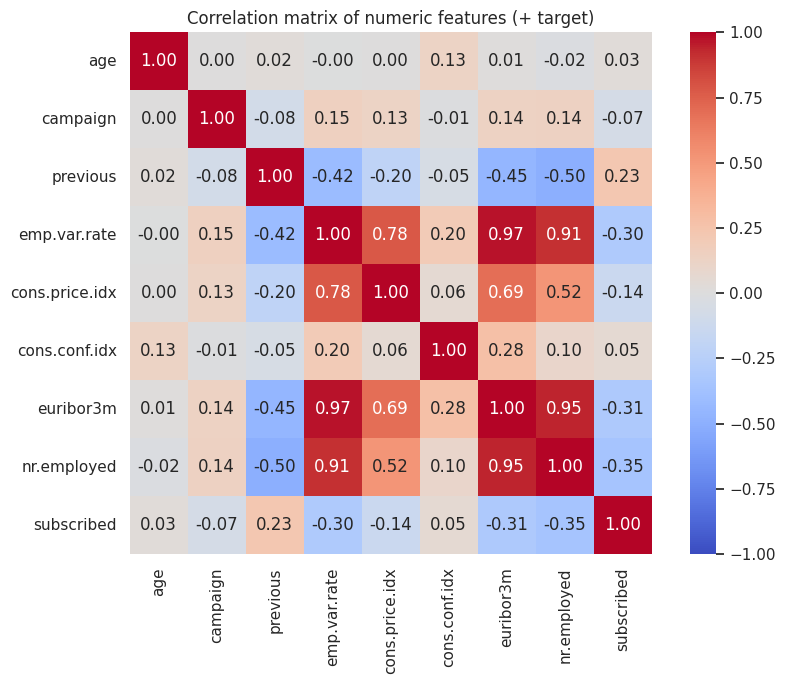

In [10]:
corr = df_eda[num_cols_eda + ["subscribed"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation matrix of numeric features (+ target)")
plt.tight_layout()
plt.show()

**Observations**
- `euribor3m`, `emp.var.rate` and `nr.employed` are almost perfectly correlated with each other (r ≈ 0.9–1.0): they are three views of the same economic cycle. This multicollinearity does not hurt tree or SVM *accuracy*, but it makes individual **logistic-regression coefficients unstable**, so they should be interpreted as a group (Section 5.3).
- Subscribers are concentrated at **low interest rates / lower employment levels** (low `euribor3m`, low `nr.employed`): when rates are low, a term-deposit offer is a relatively attractive alternative. The strongest single linear correlate of subscription is `nr.employed` (r ≈ −0.35).
- Clients with more contacts in the *current* campaign (`campaign`) are less likely to subscribe — persistence beyond a few calls has diminishing returns.

### 2.4 Inferential statistics
With 41k rows nearly *any* difference will be "statistically significant", so we report **effect sizes** alongside p-values:
- Categorical features vs. target: **chi-square test of independence** with **Cramér's V** (0 = no association, 1 = perfect).
- Numeric features vs. target: **Mann-Whitney U test** (robust to the skewed distributions seen above) with the median for each group.

In [11]:
cat_cols_test = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
rows = []
for col in cat_cols_test:
    table = pd.crosstab(df_eda[col], df_eda["y"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({"feature": col, "chi2": round(chi2, 1), "dof": dof, "p_value": f"{p:.1e}", "cramers_v": round(cramers_v, 3)})
chi_results = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
chi_results

,feature,chi2,dof,p_value,cramers_v
0,poutcome,4230.5,2,0.0e+00,0.320
1,month,3101.1,9,0.0e+00,0.274
2,job,961.2,11,4.2e-199,0.153
3,contact,862.3,1,1.5e-189,0.145
4,default,406.6,2,5.2e-89,0.099
5,education,193.1,7,3.3e-38,0.068
6,marital,122.7,3,2.1e-26,0.055
7,day_of_week,26.1,4,3.0e-05,0.025
8,housing,5.7,2,5.8e-02,0.012
9,loan,1.1,2,5.8e-01,0.005


In [12]:
rows = []
for col in num_cols_eda:
    yes, no = df_eda.loc[df_eda.y == "yes", col], df_eda.loc[df_eda.y == "no", col]
    u, p = stats.mannwhitneyu(yes, no)
    # rank-biserial correlation as an effect size (-1..1; 0 = no difference)
    effect = 2 * u / (len(yes) * len(no)) - 1
    rows.append({"feature": col, "median_yes": yes.median(), "median_no": no.median(),
                 "p_value": f"{p:.1e}", "effect_size": round(effect, 3)})
mw_results = pd.DataFrame(rows).sort_values("effect_size", key=abs, ascending=False).reset_index(drop=True)
mw_results

,feature,median_yes,median_no,p_value,effect_size
0,nr.employed,5099.100,5195.800,0.0e+00,-0.498
1,euribor3m,1.266,4.857,0.0e+00,-0.487
2,emp.var.rate,-1.800,1.100,0.0e+00,-0.434
3,cons.price.idx,93.200,93.918,9.6e-136,-0.221
4,previous,0.000,0.000,0.0e+00,0.219
5,campaign,2.000,2.000,3.4e-38,-0.110
6,cons.conf.idx,-40.400,-41.800,5.9e-17,0.075
7,age,37.000,38.000,1.6e-02,-0.022


**Interpretation**
- Eight of the ten categorical features are significantly associated with the outcome (p < 0.05); `housing` (p = 0.06) and `loan` (p = 0.58) are **not**. The **effect sizes** separate signal from noise: `poutcome` (V = 0.32) and `month` (0.27) are by far the strongest, followed by `job` (0.15), `contact` (0.15) and `default` (0.10). `education`, `marital` and `day_of_week` are statistically significant but practically tiny (V ≤ 0.07) — significant mostly because the sample is large.
- Among numeric variables, the three economic indicators show by far the largest differences (rank-biserial effect ≈ −0.43 to −0.50; the median `euribor3m` is 1.3% for subscribers vs 4.9% for non-subscribers), followed by `cons.price.idx` and `previous` (|effect| ≈ 0.22). `age` looks negligible when viewed linearly (effect −0.02), but that hides a U-shape: subscription is ~21% for clients 25 or younger, ~9% for ages 35–55, and ~47% for those over 65.
- These tests describe *individual* associations. The classifiers below can use combinations and interactions of features.

## 3. Data Preparation

Steps:
1. Remove duplicates.
2. **Drop `duration`** (data leakage — not known before the call).
3. Re-engineer `pdays`: it is sentinel-coded (999 = *not previously contacted*, not 999 real days), which would badly distort scaled/distance-based models. It is replaced by two clean features: `pdays_known` (1/0) and `days_since_contact` (real days, 0 when unknown). We verify below that `pdays` carries information beyond `previous`, so it is not simply dropped.
4. Cap `campaign` at 10 contacts to limit the influence of extreme outliers (affects only ~2% of rows).
5. Keep `"unknown"` as its own category.
6. Encode target as 1 = subscribed, 0 = not.
7. **Stratified 80/20 train-test split** (keeps the 11% positive rate in both). The test set is touched only once, for final evaluation.
8. A `ColumnTransformer` scales numeric features and one-hot encodes categoricals. It sits **inside each model's Pipeline**, so scaling statistics are learned from training folds only (no leakage during cross-validation). Scaling is essential for KNN and SVM (distance-based) and helps logistic regression converge.

In [13]:
# Is pdays (999 = not contacted) redundant with previous (# earlier contacts)? Cross-tabulate the two flags.
print(pd.crosstab(df_raw["previous"] > 0, df_raw["pdays"] != 999,
                  rownames=["previous > 0"], colnames=["pdays is a real value"]))
print(f"\nShare of rows with campaign > 10: {(df_raw['campaign'] > 10).mean():.1%}")

pdays is a real value  False  True 
previous > 0                       
False                  35563      0
True                    4110   1515

Share of rows with campaign > 10: 2.1%


In [14]:
df = df_raw.drop_duplicates().copy()
df["target"] = (df["y"] == "yes").astype(int)
df["campaign"] = df["campaign"].clip(upper=10)
df["pdays_known"] = (df["pdays"] != 999).astype(int)                 # was the client reached in a prior campaign?
df["days_since_contact"] = df["pdays"].where(df["pdays"] != 999, 0)   # real days since then (0 if never)
features = df.drop(columns=["y", "target", "duration", "pdays"])

CAT_COLS = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]
NUM_COLS = [c for c in features.columns if c not in CAT_COLS]
print("Numeric features:    ", NUM_COLS)
print("Categorical features:", CAT_COLS)

X_train, X_test, y_train, y_test = train_test_split(
    features, df["target"], test_size=0.20, stratify=df["target"], random_state=RANDOM_STATE)
print(f"\nTrain: {X_train.shape[0]:,} rows ({y_train.mean():.1%} positive) | "
      f"Test: {X_test.shape[0]:,} rows ({y_test.mean():.1%} positive)")

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])

n_encoded = make_preprocessor().fit(X_train).get_feature_names_out().shape[0]
print(f"Model input: {len(NUM_COLS) + len(CAT_COLS)} raw features -> {n_encoded} encoded columns")

Numeric features:     ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'pdays_known', 'days_since_contact']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Train: 32,940 rows (11.3% positive) | Test: 8,236 rows (11.3% positive)
Model input: 20 raw features -> 63 encoded columns


## 4. Modeling

### 4.1 Choice of evaluation metric

| Metric | Role | Why |
|---|---|---|
| **ROC-AUC** | **Primary metric** (used to choose hyperparameters in cross-validation and to compare models) | The campaign decision is *"who do we call first?"*, which is a **ranking** problem. ROC-AUC measures how well a model ranks true subscribers above non-subscribers, independent of any probability cut-off, and is not distorted by the 89/11 class imbalance. It is also the headline metric in the original study (Moro et al.), so results are comparable. |
| PR-AUC (average precision) | Secondary | More sensitive than ROC-AUC to how well the *rare* positive class is handled. |
| Recall, precision, F1 | Secondary (at the default 0.5 decision threshold) | Recall = share of real subscribers we find; precision = share of our "yes" predictions that are right. |
| Cumulative gains / lift | Business view | "If we call only the top 20% of the ranked list, what share of all subscribers do we reach?" |
| Accuracy | Reported but **not** used for selection | The majority-class baseline already scores 88.7%. |

**Reading ROC-AUC:** 0.5 = no better than random ordering, 1.0 = perfect ordering. Equivalently, it is the probability that a randomly chosen subscriber receives a higher score than a randomly chosen non-subscriber.

In [15]:
def get_scores(model, X):
    """Continuous 'likelihood of yes' score for any model (probability if available, else SVM margin)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def lift_at(y_true, scores, top_frac=0.20):
    """Share of all positives captured when contacting only the top `top_frac` highest-scored clients."""
    order = np.argsort(-scores)
    top_n = int(len(scores) * top_frac)
    return np.asarray(y_true)[order][:top_n].sum() / np.sum(y_true)

def evaluate(model, X, y):
    scores, pred = get_scores(model, X), model.predict(X)
    return {"ROC-AUC": roc_auc_score(y, scores), "PR-AUC": average_precision_score(y, scores),
            "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "Gain@20%": lift_at(y, scores, 0.20)}

### 4.2 Baseline and default models

First, a *no-skill* baseline (always predict "no"), then each of the four classifiers with **default hyperparameters**, to see what tuning adds. For KNN and SVM this uses scaled features.

In [16]:
def make_pipe(clf):
    return Pipeline([("pre", make_preprocessor()), ("clf", clf)])

default_models = {
    "Baseline (always 'no')": DummyClassifier(strategy="most_frequent"),
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(),
}
rows, fitted_defaults = [], {}
for name, clf in default_models.items():
    pipe = make_pipe(clf)
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    fitted_defaults[name] = pipe
    res = evaluate(pipe, X_test, y_test) if name != "Baseline (always 'no')" else {
        "ROC-AUC": 0.5, "PR-AUC": y_test.mean(), "Accuracy": accuracy_score(y_test, pipe.predict(X_test)),
        "Precision": 0.0, "Recall": 0.0, "F1": 0.0, "Gain@20%": 0.20}
    rows.append({"Model": name, "Fit time (s)": round(fit_time, 1),
                 "Train acc": accuracy_score(y_train, pipe.predict(X_train)), **res})
default_results = pd.DataFrame(rows).set_index("Model")
default_results.round(3)

,Fit time (s),Train acc,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,Gain@20%
Model,,,,,,,,,
Baseline (always 'no'),0.1,0.887,0.500,0.113,0.887,0.000,0.000,0.000,0.200
KNN,0.1,0.913,0.744,0.350,0.895,0.565,0.304,0.395,0.552
Logistic Regression,0.2,0.901,0.800,0.453,0.899,0.651,0.216,0.324,0.644
Decision Tree,0.2,0.995,0.625,0.182,0.840,0.310,0.338,0.323,0.406
SVM (RBF),75.8,0.906,0.693,0.405,0.901,0.663,0.246,0.358,0.551


**Reading the default results**
- Every default model *looks* good on accuracy (0.84–0.90) because of the class imbalance — but their **recall is low** (they find only a small fraction of subscribers).
- The default **decision tree overfits badly**: it memorizes the training set (train accuracy far above test accuracy) and has the weakest ROC-AUC.
- Logistic regression is the strongest default, and by far the cheapest: a fraction of a second to fit versus roughly 75 seconds for the SVM.
- Defaults are not a fair contest, though. Each algorithm has hyperparameters that control complexity; next we tune them.

### 4.3 Hyperparameter tuning (5-fold stratified cross-validation + grid search)
Each model is tuned with `GridSearchCV` using **ROC-AUC** and 5-fold stratified cross-validation **on the training set only**. Where the data is imbalanced, `class_weight="balanced"` is added as a fixed setting for the models that support it (logistic regression, decision tree, SVM), so that the minority class is not ignored. KNN has no class-weight option.

| Model | Hyperparameters searched | What they control |
|---|---|---|
| KNN | `n_neighbors`, `weights`, `p` | Neighborhood size (smoothness), distance weighting, Manhattan vs Euclidean distance |
| Logistic Regression | `C`, `penalty` (L1/L2) | Strength and type of regularization |
| Decision Tree | `max_depth`, `min_samples_leaf`, `criterion` | Tree complexity / overfitting |
| SVM (RBF) | `C`, `gamma` | Margin softness and how local the decision boundary is |

*Compute note:* an RBF SVM scales roughly quadratically with the number of rows (~75 s for one fit on all training rows here). To keep the grid search practical, the SVM grid is searched on a **stratified 6,000-row subsample** of the training data; the winning settings are then **refit on the full training set**.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_spaces = {
    "KNN": (KNeighborsClassifier(), {
        "clf__n_neighbors": [25, 50, 100, 200, 400], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}),
    "Logistic Regression": (LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE), {
        "clf__C": [0.001, 0.01, 0.1, 1, 10, 100], "clf__penalty": ["l1", "l2"]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE), {
        "clf__max_depth": [4, 6, 8, 10, 12, None], "clf__min_samples_leaf": [50, 100, 200, 400, 800],
        "clf__criterion": ["gini", "entropy"]}),
}
searches, tuning_time = {}, {}
for name, (clf, grid) in search_spaces.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(make_pipe(clf), grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    tuning_time[name] = time.perf_counter() - t0
    searches[name] = gs
    print(f"{name:20s} best CV ROC-AUC = {gs.best_score_:.4f}  "
          f"params = { {k.replace('clf__', ''): v for k, v in gs.best_params_.items()} }  ({tuning_time[name]:.0f}s)")

KNN                  best CV ROC-AUC = 0.7882  params = {'n_neighbors': 400, 'p': 1, 'weights': 'uniform'}  (293s)


Logistic Regression  best CV ROC-AUC = 0.7906  params = {'C': 0.1, 'penalty': 'l1'}  (53s)


Decision Tree        best CV ROC-AUC = 0.7859  params = {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 200}  (45s)


In [18]:
# SVM: grid search on a stratified subsample, then refit the best settings on the full training set
X_svm, _, y_svm, _ = train_test_split(X_train, y_train, train_size=6000, stratify=y_train, random_state=RANDOM_STATE)
svm_grid = {"clf__C": [1, 10, 100], "clf__gamma": [0.0003, 0.001, 0.003, 0.01]}

t0 = time.perf_counter()
svm_search = GridSearchCV(make_pipe(SVC(kernel="rbf", class_weight="balanced")), svm_grid,
                          scoring="roc_auc", cv=cv, n_jobs=-1, refit=False)
svm_search.fit(X_svm, y_svm)
svm_search_time = time.perf_counter() - t0
print(f"SVM grid search (6,000-row subsample): best CV ROC-AUC = {svm_search.best_score_:.4f}  "
      f"params = { {k.replace('clf__', ''): v for k, v in svm_search.best_params_.items()} }  "
      f"({svm_search_time:.0f}s)")

t0 = time.perf_counter()
svm_final = make_pipe(SVC(kernel="rbf", class_weight="balanced", **{k.replace('clf__', ''): v for k, v in svm_search.best_params_.items()}))
svm_final.fit(X_train, y_train)
svm_refit_time = time.perf_counter() - t0
# Total SVM cost = grid search on the subsample + refit on all training rows (comparable to the other models)
tuning_time["SVM (RBF)"] = svm_search_time + svm_refit_time
print(f"Refit on all {len(X_train):,} training rows: {svm_refit_time:.0f}s  (total SVM tuning + fit: {tuning_time['SVM (RBF)']:.0f}s)")

SVM grid search (6,000-row subsample): best CV ROC-AUC = 0.7756  params = {'C': 10, 'gamma': 0.001}  (81s)


Refit on all 32,940 training rows: 74s  (total SVM tuning + fit: 155s)


In [19]:
# Collect the tuned models in one dictionary
tuned_models = {name: gs.best_estimator_ for name, gs in searches.items()}
tuned_models["SVM (RBF)"] = svm_final

# Cross-validation results table
cv_rows = []
for name, gs in searches.items():
    i = gs.best_index_
    cv_rows.append({"Model": name, "CV ROC-AUC (mean)": gs.cv_results_["mean_test_score"][i],
                    "CV ROC-AUC (std)": gs.cv_results_["std_test_score"][i],
                    "Best parameters": {k.replace('clf__', ''): v for k, v in gs.best_params_.items()}})
res = svm_search.cv_results_; i = svm_search.best_index_
cv_rows.append({"Model": "SVM (RBF)", "CV ROC-AUC (mean)": res["mean_test_score"][i], "CV ROC-AUC (std)": res["std_test_score"][i],
                "Best parameters": {k.replace('clf__', ''): v for k, v in svm_search.best_params_.items()}})
cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table.style.format({"CV ROC-AUC (mean)": "{:.4f}", "CV ROC-AUC (std)": "{:.4f}"})

,CV ROC-AUC (mean),CV ROC-AUC (std),Best parameters
Model,,,
KNN,0.7882,0.0095,"{'n_neighbors': 400, 'p': 1, 'weights': 'uniform'}"
Logistic Regression,0.7906,0.0077,"{'C': 0.1, 'penalty': 'l1'}"
Decision Tree,0.7859,0.0090,"{'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 200}"
SVM (RBF),0.7756,0.0196,"{'C': 10, 'gamma': 0.001}"


**Reading the cross-validation results:** the cross-validated ROC-AUC (mean ± standard deviation across 5 folds) is the fair, test-set-free basis for comparing the tuned models. Small gaps relative to the fold-to-fold standard deviation should not be over-interpreted. (The SVM figure comes from the 6,000-row subsample, so it is a slightly pessimistic estimate for the SVM refit on all data.)

**In this run:** logistic regression has the highest cross-validated score (0.791 ± 0.008), followed by KNN (0.788), the decision tree (0.786) and the SVM (0.776 ± 0.020). The gaps between the first three are about one fold-standard-deviation, i.e. a statistical tie; the SVM's wider spread reflects the small 6,000-row tuning subsample. Tuned settings: KNN `n_neighbors = 400` with Manhattan distance (smooth, heavily averaged neighborhoods, a sign the signal is simple and noisy), LR with L1 penalty and `C = 0.1` (moderate sparsity), tree `max_depth = 10` with `min_samples_leaf = 200` (leaves must hold at least 200 clients to curb overfitting), SVM `C = 10`, `gamma = 0.001` (a very smooth, nearly linear boundary).

## 5. Evaluation on the Held-Out Test Set

In [20]:
test_rows = []
for name, model in tuned_models.items():
    test_rows.append({"Model": name, **evaluate(model, X_test, y_test)})
test_results = pd.DataFrame(test_rows).set_index("Model")
test_results["CV ROC-AUC"] = cv_table["CV ROC-AUC (mean)"]
test_results["Tuning+fit time (s)"] = pd.Series(tuning_time).round(0)
test_results.sort_values("ROC-AUC", ascending=False).round(3)

,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,Gain@20%,CV ROC-AUC,Tuning+fit time (s)
Model,,,,,,,,,
Decision Tree,0.803,0.466,0.836,0.367,0.626,0.463,0.634,0.786,45.0
Logistic Regression,0.800,0.447,0.831,0.360,0.647,0.463,0.644,0.791,53.0
KNN,0.799,0.454,0.898,0.676,0.191,0.297,0.643,0.788,293.0
SVM (RBF),0.790,0.407,0.835,0.368,0.639,0.467,0.641,0.776,155.0


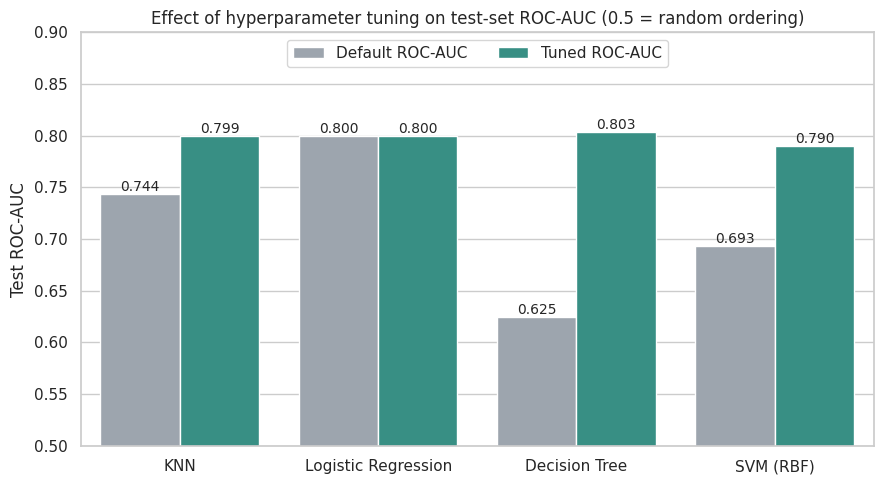

In [21]:
# Default vs. tuned: how much did tuning help?
compare = pd.DataFrame({
    "Default ROC-AUC": default_results.loc[["KNN", "Logistic Regression", "Decision Tree", "SVM (RBF)"], "ROC-AUC"],
    "Tuned ROC-AUC": test_results["ROC-AUC"]})
compare_long = compare.reset_index().melt(id_vars="Model", var_name="Version", value_name="Test ROC-AUC")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=compare_long, x="Model", y="Test ROC-AUC", hue="Version", palette=["#9aa5b1", "#2a9d8f"], ax=ax)
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=10)
ax.set_ylim(0.5, 0.90)
ax.set_title("Effect of hyperparameter tuning on test-set ROC-AUC (0.5 = random ordering)")
ax.legend(loc="upper center", ncol=2, title="")
ax.set_ylabel("Test ROC-AUC")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 5.1 ROC and precision-recall curves

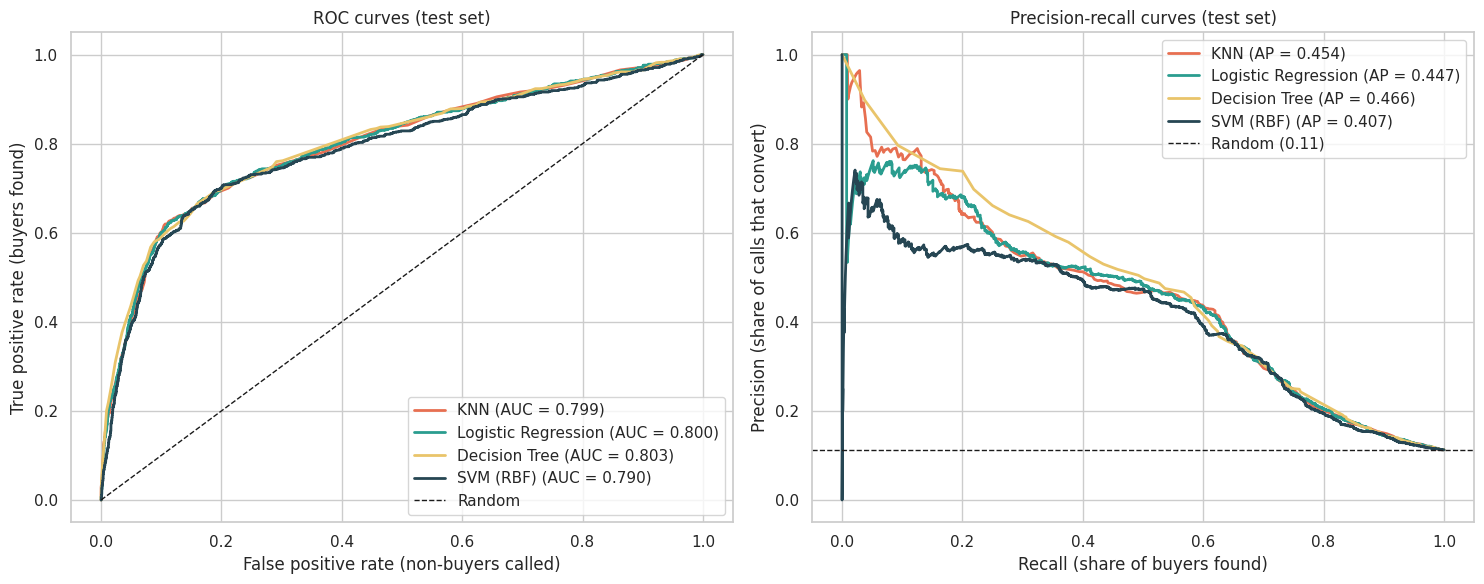

In [22]:
colors = {"KNN": "#e76f51", "Logistic Regression": "#2a9d8f", "Decision Tree": "#e9c46a", "SVM (RBF)": "#264653"}
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, model in tuned_models.items():
    s = get_scores(model, X_test)
    fpr, tpr, _ = roc_curve(y_test, s)
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
    axes[1].plot(rec, prec, color=colors[name], lw=2, label=f"{name} (AP = {average_precision_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random")
axes[0].set(title="ROC curves (test set)", xlabel="False positive rate (non-buyers called)", ylabel="True positive rate (buyers found)")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Random ({y_test.mean():.2f})")
axes[1].set(title="Precision-recall curves (test set)", xlabel="Recall (share of buyers found)", ylabel="Precision (share of calls that convert)")
for ax in axes: ax.legend(loc="best")
plt.tight_layout()
plt.show()

### 5.2 Confusion matrices and the business view (cumulative gains)

Confusion matrices below use each model's default 0.5 decision rule. Because the class-weighted models deliberately favour recall, they flag many more clients as "yes" (more false positives) than KNN does.

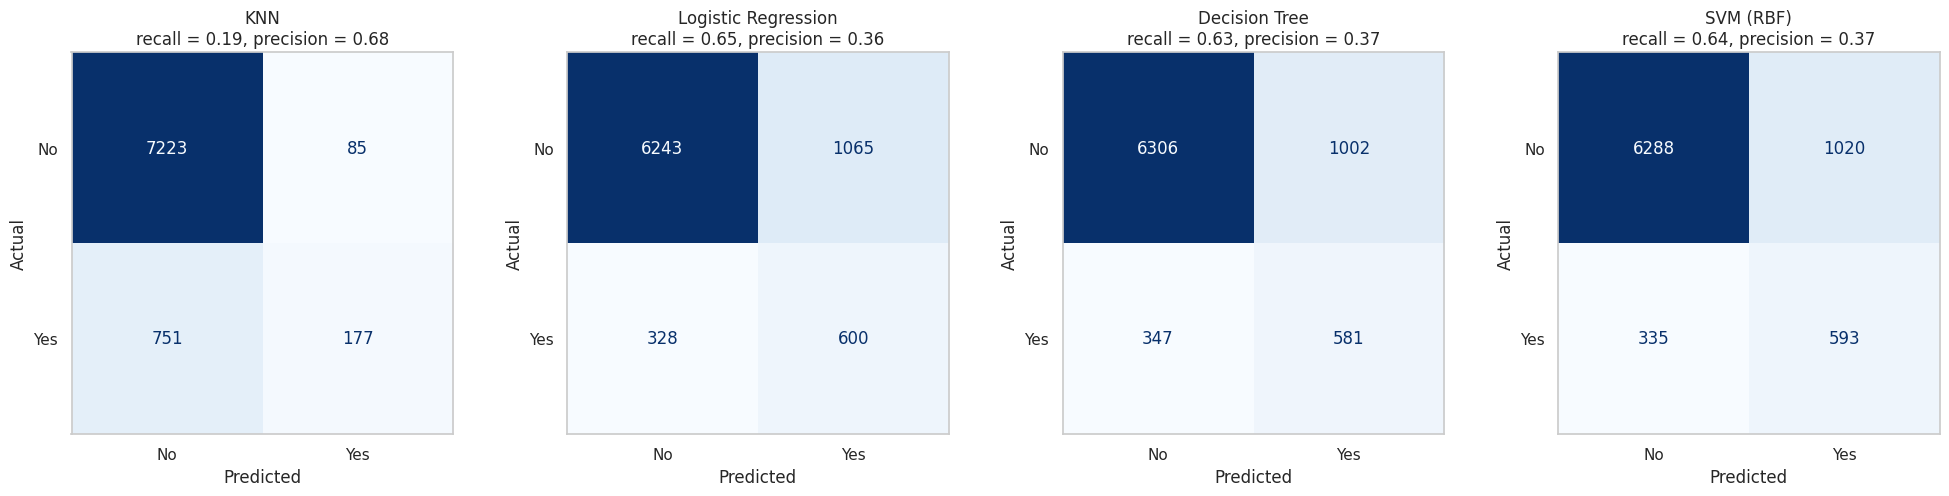

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, (name, model) in zip(axes, tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["No", "Yes"],
                                          cmap="Blues", colorbar=False, ax=ax)
    r = recall_score(y_test, model.predict(X_test)); p = precision_score(y_test, model.predict(X_test), zero_division=0)
    ax.set_title(f"{name}\nrecall = {r:.2f}, precision = {p:.2f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.grid(False)
plt.tight_layout()
plt.show()

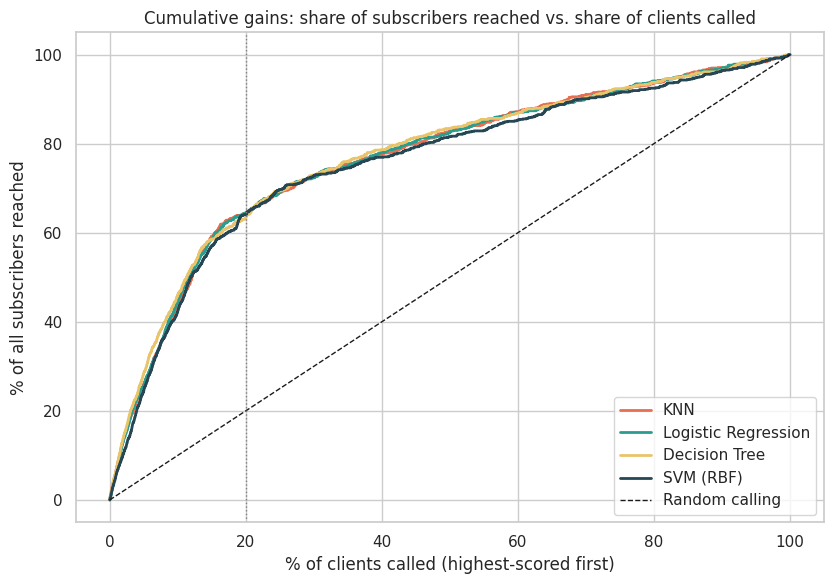

Share of all subscribers reached when calling only the top X% of the ranked list:


,KNN,Logistic Regression,Decision Tree,SVM (RBF)
Top 10% of list,43.5%,44.6%,45.9%,42.2%
Top 20% of list,64.3%,64.4%,63.4%,64.1%
Top 30% of list,72.4%,72.3%,73.0%,72.7%
Top 50% of list,82.9%,82.4%,83.4%,81.6%


In [24]:
def gains_curve(y_true, scores):
    order = np.argsort(-scores)
    cum_pos = np.cumsum(np.asarray(y_true)[order]) / np.sum(y_true)
    pct_contacted = np.arange(1, len(scores) + 1) / len(scores)
    return pct_contacted, cum_pos

fig, ax = plt.subplots(figsize=(8.5, 6))
for name, model in tuned_models.items():
    x, g = gains_curve(y_test, get_scores(model, X_test))
    ax.plot(x * 100, g * 100, lw=2, color=colors[name], label=name)
ax.plot([0, 100], [0, 100], "k--", lw=1, label="Random calling")
ax.axvline(20, color="grey", ls=":", lw=1)
ax.set(title="Cumulative gains: share of subscribers reached vs. share of clients called",
       xlabel="% of clients called (highest-scored first)", ylabel="% of all subscribers reached")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

gain_table = pd.DataFrame({name: {f"Top {int(f*100)}% of list": lift_at(y_test, get_scores(m, X_test), f)
                                  for f in (0.1, 0.2, 0.3, 0.5)} for name, m in tuned_models.items()})
print("Share of all subscribers reached when calling only the top X% of the ranked list:")
(gain_table * 100).round(1).astype(str).add("%")

**Reading the test-set results**
- **All four tuned models are tied on ranking quality** (ROC-AUC 0.79–0.80; the PR-AUC range is 0.41–0.47). With roughly 930 subscribers in the test set, differences of ~0.01 AUC are within sampling noise, so the choice between them should rest on speed, interpretability and stability (Section 6.2).
- **Why accuracy looks "worse" after tuning:** the class-weighted models (LR, tree, SVM) deliberately flag more clients as "yes" to catch more subscribers. Their accuracy falls to ~0.83 versus 0.89 for the always-"no" baseline, but their **recall rises from ~0.2 to ~0.65**. That trade is the point: for a campaign, missing a buyer is costlier than one extra call.
- **KNN** (no class-weight option) stays conservative: high precision (0.68) but it finds only 19% of subscribers at the 0.5 cut-off. Its *ranking* is as good as the others' (AUC 0.799), which is why it matches them in the gains chart.
- **Gains table:** calling the top 10% / 20% / 30% / 50% of the ranked list reaches roughly 44% / 64% / 72% / 82% of subscribers for every model.

### 5.3 Interpreting the models
**Logistic regression** is the most interpretable model. Features were standardized, so a numeric coefficient is the change in the *log-odds* of subscribing per **one standard deviation** increase; categorical coefficients are relative to the other categories of the same variable (regularization shrinks them toward zero). **Odds ratio = exp(coefficient)**: 2.0 means the odds of subscribing double, 0.5 means they halve, all else equal.

Penalty: l1, C = 0.1 -> 43 of 63 coefficients are non-zero


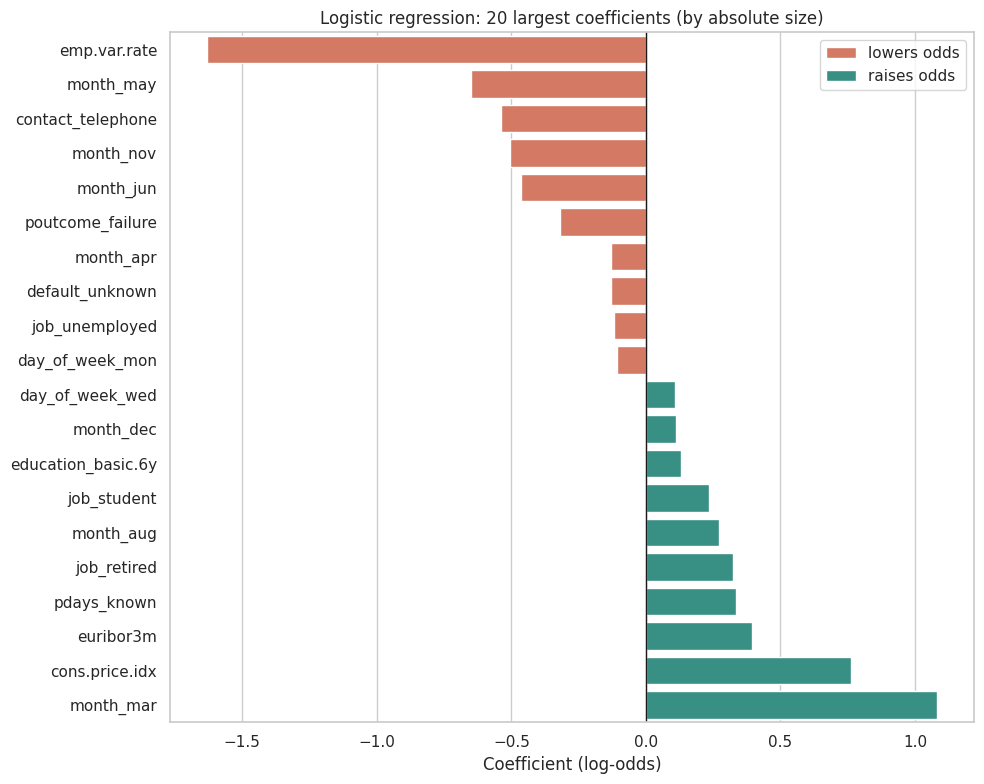

,coefficient,odds_ratio
month_mar,1.08,2.95
cons.price.idx,0.76,2.14
euribor3m,0.39,1.48
pdays_known,0.34,1.40
job_retired,0.32,1.38
month_aug,0.27,1.31
job_student,0.23,1.26
education_basic.6y,0.13,1.14
month_dec,0.11,1.12
day_of_week_wed,0.11,1.11


In [25]:
lr_pipe = tuned_models["Logistic Regression"]
feat_names = [n.split("__", 1)[1] for n in lr_pipe.named_steps["pre"].get_feature_names_out()]
coef = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=feat_names)
coef_df = pd.DataFrame({"coefficient": coef, "odds_ratio": np.exp(coef)})
coef_df = coef_df[coef_df["coefficient"] != 0]
print(f"Penalty: {lr_pipe.named_steps['clf'].penalty}, C = {lr_pipe.named_steps['clf'].C} "
      f"-> {len(coef_df)} of {len(coef)} coefficients are non-zero")

top = coef_df.reindex(coef_df["coefficient"].abs().nlargest(20).index).sort_values("coefficient")
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(x=top["coefficient"], y=top.index, hue=(top["coefficient"] > 0).map({True: "raises odds", False: "lowers odds"}),
            palette={"raises odds": "#2a9d8f", "lowers odds": "#e76f51"}, dodge=False, ax=ax)
ax.axvline(0, color="k", lw=1)
ax.set(title="Logistic regression: 20 largest coefficients (by absolute size)",
       xlabel="Coefficient (log-odds)", ylabel="")
ax.legend(title="")
plt.tight_layout()
plt.show()
top.assign(odds_ratio=top["odds_ratio"].round(2), coefficient=top["coefficient"].round(2)).iloc[::-1]

**How to read these coefficients**
- Odds ratios (the table above): **month_mar 2.95** means that, all else equal, contact in March multiplies the odds of subscribing by about 3 relative to the average month; **month_may 0.52** halves them. **contact_telephone 0.58** means landline contacts have about 40% lower odds than cellular. **job_retired 1.38** and **job_student 1.26** raise the odds by 38% and 26%. **poutcome_failure 0.73** lowers them by 27%.
- **`pdays_known` (1.40) mostly reflects "was a previous-campaign success".** Of the 1,515 clients with a known `pdays`, 1,373 (91%) had a successful previous campaign and the other 142 a failed one; every past success has a known `pdays`. The L1 penalty found this feature and `poutcome_success` redundant and kept only one (the other was shrunk to exactly zero), which is why `poutcome_success` is absent from the plot even though previous success is the strongest single signal in the raw data.
- **Do not interpret the three economic indicators one by one.** `emp.var.rate` (−1.63), `cons.price.idx` (+0.76) and `euribor3m` (+0.39) have *opposite signs* even though they move together (r ≈ 0.9–1.0), a classic multicollinearity effect; `nr.employed` was shrunk to zero. Read them as one block, "the economic cycle", which matters a lot. Their individual signs and sizes are not reliable.
- With L1 regularization (C = 0.1), 43 of 63 coefficients are non-zero and category effects are shrunk toward zero, so these are best used for ranking drivers, not as exact effect sizes. Coefficients for numeric variables are per one standard deviation.

**Decision tree** — importance of each feature in the tuned tree, and the first three levels of its rules.

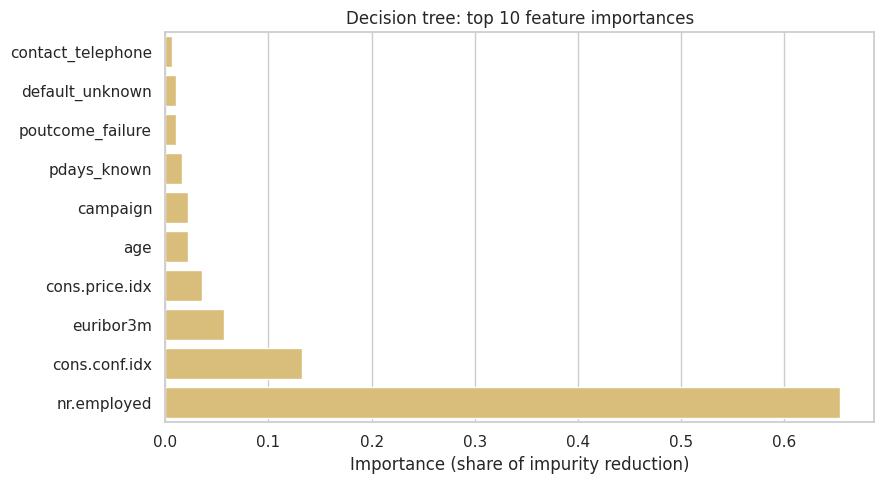

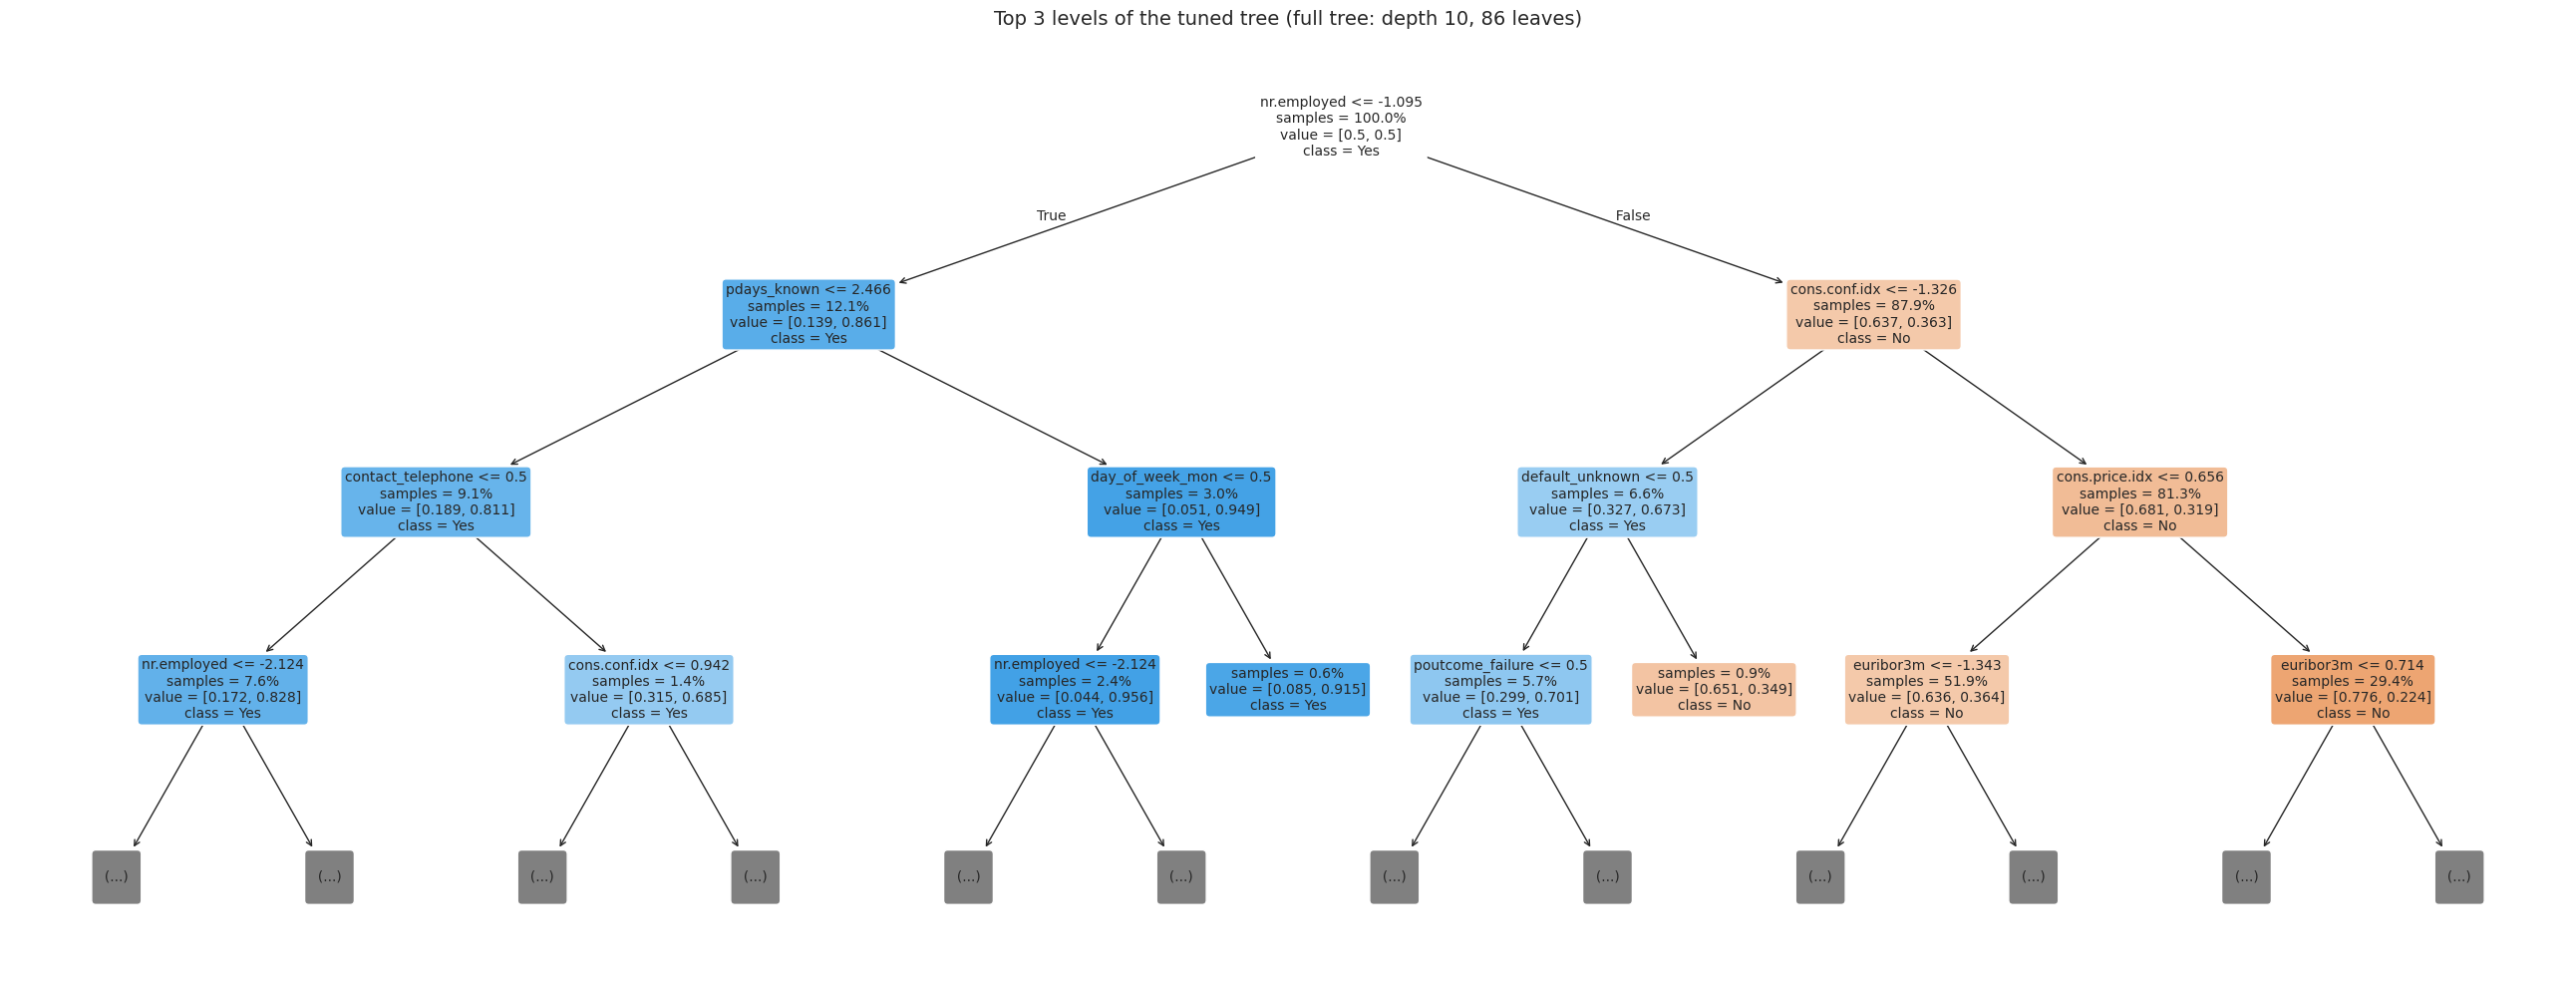

In [26]:
dt_pipe = tuned_models["Decision Tree"]
dt = dt_pipe.named_steps["clf"]
imp = pd.Series(dt.feature_importances_, index=feat_names).sort_values(ascending=False)
top_imp = imp.head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top_imp.values, y=top_imp.index, color="#e9c46a", ax=ax)
ax.set(title="Decision tree: top 10 feature importances", xlabel="Importance (share of impurity reduction)", ylabel="")
plt.tight_layout()
plt.show()

# draw only the top 3 levels so the picture stays readable (thresholds are in standardized units)
fig, ax = plt.subplots(figsize=(26, 10))
plot_tree(dt, max_depth=3, feature_names=feat_names, class_names=["No", "Yes"], filled=True, rounded=True,
          impurity=False, proportion=True, fontsize=10, ax=ax)
ax.set_title(f"Top 3 levels of the tuned tree (full tree: depth {dt.get_depth()}, {dt.get_n_leaves()} leaves)", fontsize=14)
plt.tight_layout()
plt.show()

**Reading the tree:** the root split is on `nr.employed` (a standardized threshold of −1.1 means about one standard deviation *below* the average employment level, i.e. the economy is weak/rates are low), and that variable alone accounts for roughly two-thirds of the tree's importance, followed by `cons.conf.idx` and `euribor3m`. In other words, **the tree mostly learns "when" a call was made**, with `pdays_known`, `contact` type and `default_unknown` refining the split. The `value = [..]` shown in each box is class-weighted (hence 0.5/0.5 at the root), while `samples` is the real share of clients. This heavy reliance on economic thresholds is exactly why the tree fails the chronological test below.

**KNN and SVM** are not directly interpretable: KNN predicts from the most similar past clients, and the RBF-kernel SVM draws a non-linear boundary in a high-dimensional space with no per-feature coefficients. Their value in this project is as accuracy benchmarks, which is what the comparison tables above show.

## 6. Robustness Checks

### 6.1 How much would call `duration` inflate the results?
We exclude `duration` because it is unknown until the call is over. To show *why* that matters, here is the same tuned logistic regression and decision tree with `duration` added back.

In [27]:
leaky_features = df.drop(columns=["y", "target", "pdays"])
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    leaky_features, df["target"], test_size=0.20, stratify=df["target"], random_state=RANDOM_STATE)

NUM_COLS_LEAK = NUM_COLS + ["duration"]
def make_preprocessor_leak():
    return ColumnTransformer([("num", StandardScaler(), NUM_COLS_LEAK),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])

rows = []
for name in ["Logistic Regression", "Decision Tree"]:
    clf = clone(tuned_models[name].named_steps["clf"])
    pipe_leak = Pipeline([("pre", make_preprocessor_leak()), ("clf", clf)]).fit(Xl_train, yl_train)
    rows.append({"Model": name, "ROC-AUC without duration (realistic)": test_results.loc[name, "ROC-AUC"],
                 "ROC-AUC with duration (leaky)": roc_auc_score(yl_test, get_scores(pipe_leak, Xl_test))})
pd.DataFrame(rows).set_index("Model").round(3)

,ROC-AUC without duration (realistic),ROC-AUC with duration (leaky)
Model,,
Logistic Regression,0.800,0.94
Decision Tree,0.803,0.94


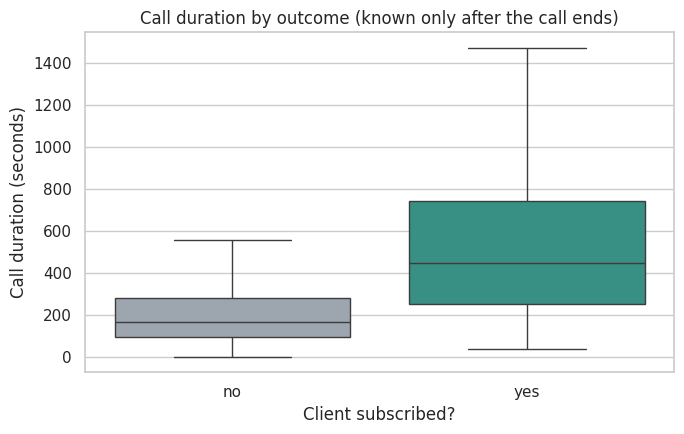

In [28]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df_eda, x="y", y="duration", order=["no", "yes"], palette=["#9aa5b1", "#2a9d8f"], showfliers=False, ax=ax)
ax.set(title="Call duration by outcome (known only after the call ends)", xlabel="Client subscribed?", ylabel="Call duration (seconds)")
plt.tight_layout()
plt.show()

Adding `duration` lifts the AUC dramatically, but it is circular: a call that ends in a sale is naturally longer, and the length can't be known when the call list is built. Using it would overstate real-world performance, so it stays out of the models.

### 6.2 Does performance hold up over time?
The data is ordered by date. A random split mixes 2008–2010 together; in real use a model is trained on the past and used on the future. As a stress test, we train on the **first 80%** of calls (chronologically) and test on the **last 20%**, re-using each model's tuned hyperparameters.

In [29]:
cut = int(len(features) * 0.8)                       # df keeps the original (chronological) order
Xt_train, Xt_test = features.iloc[:cut], features.iloc[cut:]
yt_train, yt_test = df["target"].iloc[:cut], df["target"].iloc[cut:]
print(f"Chronological split -> train: {len(Xt_train):,} rows ({yt_train.mean():.1%} positive) | "
      f"test: {len(Xt_test):,} rows ({yt_test.mean():.1%} positive)")

rows = []
for name, model in tuned_models.items():
    m = clone(model).fit(Xt_train, yt_train)
    rows.append({"Model": name, "ROC-AUC (random split)": test_results.loc[name, "ROC-AUC"],
                 "ROC-AUC (chronological split)": roc_auc_score(yt_test, get_scores(m, Xt_test)),
                 "Gain@20% (chronological)": lift_at(yt_test, get_scores(m, Xt_test), 0.20)})
temporal = pd.DataFrame(rows).set_index("Model")
temporal.round(3)

Chronological split -> train: 32,940 rows (6.4% positive) | test: 8,236 rows (30.8% positive)


,ROC-AUC (random split),ROC-AUC (chronological split),Gain@20% (chronological)
Model,,,
KNN,0.799,0.716,0.378
Logistic Regression,0.800,0.751,0.384
Decision Tree,0.803,0.517,0.189
SVM (RBF),0.790,0.635,0.272


**Interpretation:** this is a harsh test, partly because the world changed: only 6.4% of calls in the training period succeeded versus 30.8% in the final period (likely reflecting low interest rates after 2009 and different campaign targeting). All models lose accuracy, but not equally:
- **Logistic regression degrades least** (0.800 → 0.751) and still reaches ~38% of subscribers with the top 20% of calls.
- **KNN** is next (0.716).
- **The SVM (0.635) and especially the decision tree (0.517, no better than random)** had learned economic-level cut-offs that don't extend to conditions they never saw during training.

This supports choosing logistic regression, and it is a warning that *any* model built on this data must be re-validated and refreshed as economic conditions change.

## 7. Findings

*Written for a non-technical reader (e.g. campaign managers). "Subscription" means a client taking out the term deposit.*

### The headline
**A simple, fast model can roughly triple the efficiency of the call center.** Using only information the bank has *before* dialing, the model ranks clients so that calling the **top 20% of the list reaches about 64% of all people who would subscribe** (random calling would reach 20%). The **top 10% reaches about 44%.**

### 1. All four classifiers perform about the same, so the choice should be made on other grounds
| Model | Test ROC-AUC | Cross-validated ROC-AUC | Top-20% reach | Time to tune + fit | Time stability (chronological test) |
|---|---|---|---|---|---|
| Logistic Regression | 0.800 | **0.791** | 64% | 53 s | **0.751** |
| Decision Tree | 0.803 | 0.786 | 63% | 45 s | 0.517 |
| KNN | 0.799 | 0.788 | 64% | 293 s | 0.716 |
| SVM (RBF) | 0.790 | 0.776 | 64% | 155 s* | 0.635 |

*SVM: grid search on a 6,000-row subsample (81 s) plus refit of the winning settings on all training data (74 s).

On the random hold-out test the differences (≤ 0.013 AUC) are within the fold-to-fold noise of cross-validation (SD ≈ 0.008–0.010), and the test set contains only ~930 subscribers, so **no model is meaningfully "best" on accuracy alone.** Tuning mattered a lot for the decision tree (0.625 → 0.803), the SVM (0.693 → 0.790) and KNN (0.744 → 0.799), but logistic regression was already near its ceiling at default settings.

### 2. Recommended model: Logistic Regression
- **Equal accuracy, lowest cost:** it trains in a fraction of a second and is the cheapest to retrain and run.
- **Explainable:** each factor has a direction and size that managers can read (Section 5.3). KNN and the SVM are black boxes with no accuracy benefit.
- **Most reliable over time:** in the stress test where models learn from the past and are tested on the *most recent* calls, logistic regression held up (AUC 0.75) while the decision tree dropped to near-random (0.52) and the SVM to 0.64. A likely reason is that trees and SVMs latch onto the exact interest-rate levels seen in training (the tree's top split is on an economic indicator), which don't carry over when the economy moves.

### 3. What drives a client's decision to subscribe
| Finding | Evidence |
|---|---|
| **Previous customers who said yes before are by far the best prospects** | 65% subscribed vs 9% of first-time contacts (`poutcome`: Cramér's V 0.32, the strongest categorical factor) |
| **Cell phones convert much better than landlines** | 14.7% vs 5.2% (2.8×); odds of subscribing are about 40% lower on landline, all else equal |
| **Economic conditions matter more than any client trait** | Subscribers were reached when interest rates were low (median euribor 1.3% vs 4.9%); the three economic indicators had the largest effects of all numeric features |
| **Students and retirees are the most receptive groups** | 31% and 25% vs 11% overall; blue-collar (7%) and services (8%) are the least |
| **Calling the same person again and again pays less and less** | Conversion falls from 13% on the 1st contact to ~4% by the 10th |
| **Clients whose credit-default status is "unknown" rarely subscribe** | ~5% vs ~13% for confirmed "no default" |
| **Month matters, but it is not a free lever** | March, September, October and December convert at 44–51%, but with only 182–718 calls each and in low-interest-rate periods, so part of this is the economy and campaign design rather than the calendar |
| **Day of week, housing loan, personal loan are not useful** | Tiny or non-significant effects (housing p = 0.06, loan p = 0.58) |

### 4. Be realistic about what the model can and cannot do
- At the default cut-off the class-weighted models find about **65% of subscribers**, and about **1 in 3 of the clients they flag actually subscribes** (precision ≈ 0.36 versus a base rate of 0.11, i.e. ~3.2× better than random). That is a useful improvement, but still means roughly two of every three flagged calls will not convert.
- About **36% of eventual subscribers are *not* in the top 20%** of any model's list. Cutting the list too aggressively gives up real sales.
- AUC ≈ 0.80 is solid but not exceptional. The much higher figures seen in the literature for this data (~0.94) rely on the **call duration**, which is only known after the call, so they cannot be used for planning (reproduced in Section 6.1).
- This data covers 2008–2010, a financial-crisis period with unusual interest rates. Patterns may not hold today.

## 8. Next Steps & Recommendations

### Recommended actions for the campaign team
1. **Score and rank the call list with the logistic regression model** and work the list from the top down. Start with the top 20–30% (reaches ~64–72% of likely subscribers) rather than calling everyone.
2. **Prioritise past subscribers first**, then students and retirees, and **use mobile numbers** wherever the client has one.
3. **Cap repeated attempts per client.** After roughly 3–5 unsuccessful contacts the expected return drops sharply.
4. **Set the cut-off with economics, not a default.** Decide the cost of a call and the value of a deposit; call everyone whose predicted likelihood is above the break-even point. This notebook uses 0.5 only for illustration.
5. **Do not rely on call length or day of week** to plan campaigns; neither helps before the call (duration) or has any real effect (day of week).
6. **Treat timing recommendations cautiously.** Launching more campaigns in low-interest-rate periods is plausible, but the month effect here is mixed up with the economic cycle and should be tested before acting on it.

### Next steps for the data science work
- **Run a controlled pilot (A/B test):** call one group in model-ranked order and another in the current order, and compare deposits per 100 calls. This is the only way to confirm the real-world gain.
- **Add richer client data.** The original study used account balance, tenure, product holdings and web-banking behaviour, which are not in this public file and likely carry stronger signal than demographics.
- **Validate over time and monitor drift.** Retrain periodically, evaluate on a chronological hold-out, and track whether the model's top-20% reach decays as interest rates change. Consider dropping or re-engineering the economic indicators for a model meant to survive regime changes.
- **Calibrate the probabilities** (e.g. with `CalibratedClassifierCV`) so scores can be read as true likelihoods when setting the cost-based cut-off.
- **Widen a few search grids.** The KNN optimum (`n_neighbors = 400`) sits at the top edge of its grid, and the SVM was tuned on a subsample; both could move slightly. I would not expect this to change the conclusion, as KNN's CV score only moved from 0.785 to 0.788 when going from 100 to 400 neighbors.
- **Try stronger model families** such as gradient-boosted trees or ensembles, which often beat all four classifiers compared here on tabular data, and use SHAP for explanations.
- **Review fairness and privacy.** Age, marital status and similar attributes should be checked against banking/consumer-protection regulation (e.g. GDPR) before being used to target or exclude clients; this model has not been tested without them, so that would be a sensible follow-up.